# Star Classification Using Machine Learning
Goal: classify an observation as STAR, GALAXY, or QSO.



In [ ]:
import os, json, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)

In [5]:
%pip install scikit-learn==1.9.0


Note: you may need to restart the kernel to use updated packages.


In [6]:
import sklearn
print(sklearn.__version__)

1.9.0


## 1. Load and inspect the dataset

In [7]:
df = pd.read_csv("star_classification.csv")
print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nSummary:")
display(df.describe().T)
df.info()

Shape: (100000, 18)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842



Columns: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']

Data types:
obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
rerun_ID         int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
class           object
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
dtype: object

Summary:


,count,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,1.237665e+18,8.438560e+12,1.237646e+18,1.237659e+18,1.237663e+18,1.237668e+18,1.237681e+18
alpha,100000.0,1.776291e+02,9.650224e+01,5.527828e-03,1.275182e+02,1.809007e+02,2.338950e+02,3.599998e+02
delta,100000.0,2.413530e+01,1.964467e+01,-1.878533e+01,5.146771e+00,2.364592e+01,3.990155e+01,8.300052e+01
u,100000.0,2.198047e+01,3.176929e+01,-9.999000e+03,2.035235e+01,2.217914e+01,2.368744e+01,3.278139e+01
g,100000.0,2.053139e+01,3.175029e+01,-9.999000e+03,1.896523e+01,2.109983e+01,2.212377e+01,3.160224e+01
r,100000.0,1.964576e+01,1.854760e+00,9.822070e+00,1.813583e+01,2.012529e+01,2.104478e+01,2.957186e+01
i,100000.0,1.908485e+01,1.757895e+00,9.469903e+00,1.773228e+01,1.940514e+01,2.039650e+01,3.214147e+01
z,100000.0,1.866881e+01,3.172815e+01,-9.999000e+03,1.746068e+01,1.900460e+01,1.992112e+01,2.938374e+01
run_ID,100000.0,4.481366e+03,1.964765e+03,1.090000e+02,3.187000e+03,4.188000e+03,5.326000e+03,8.162000e+03
rerun_ID,100000.0,3.010000e+02,0.000000e+00,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

## 2. Missing values and duplicates

In [8]:
# DUPLICATE AND MISSING VALUE CHECK

print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values in each column:")
display(df.isnull().sum())

if df.isnull().sum().sum() == 0:
    print("\nNo missing values found in this dataset.")
else:
    print("\nMissing values are present in the dataset.")

Duplicate rows: 0

Missing values in each column:


obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64


No missing values found in this dataset.


## 3. Target class distribution

class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64
class
GALAXY    59.44
STAR      21.59
QSO       18.96
Name: proportion, dtype: float64


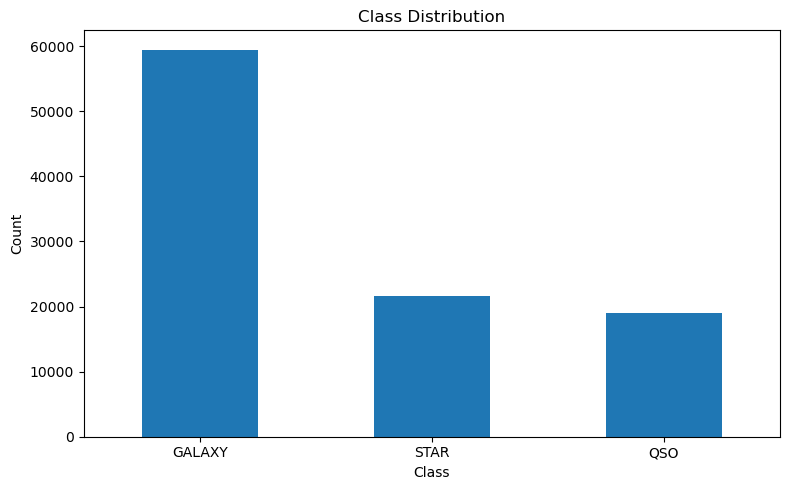

In [9]:
if "class" not in df.columns:
    raise ValueError("Target column 'class' was not found.")
print(df["class"].value_counts())
print((df["class"].value_counts(normalize=True) * 100).round(2))
df["class"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Select features and target

In [10]:
FEATURES = ["u", "g", "r", "i", "z"]
TARGET = "class"
missing_columns = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

# IDs and survey metadata are excluded from the first model.
data = df[FEATURES + [TARGET]].copy()
data = data.dropna(subset=[TARGET])
for col in FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")
X = data[FEATURES]
y = data[TARGET].astype(str).str.strip().str.upper()
print("Features:", FEATURES)
print("Classes:", sorted(y.unique()))
print("Rows for modelling:", len(data))
display(X.head())

Features: ['u', 'g', 'r', 'i', 'z']
Classes: ['GALAXY', 'QSO', 'STAR']
Rows for modelling: 100000


,u,g,r,i,z
0,23.87882,22.27530,20.39501,19.16573,18.79371
1,24.77759,22.83188,22.58444,21.16812,21.61427
2,25.26307,22.66389,20.60976,19.34857,18.94827
3,22.13682,23.77656,21.61162,20.50454,19.25010
4,19.43718,17.58028,16.49747,15.97711,15.54461


## 5. Feature distributions

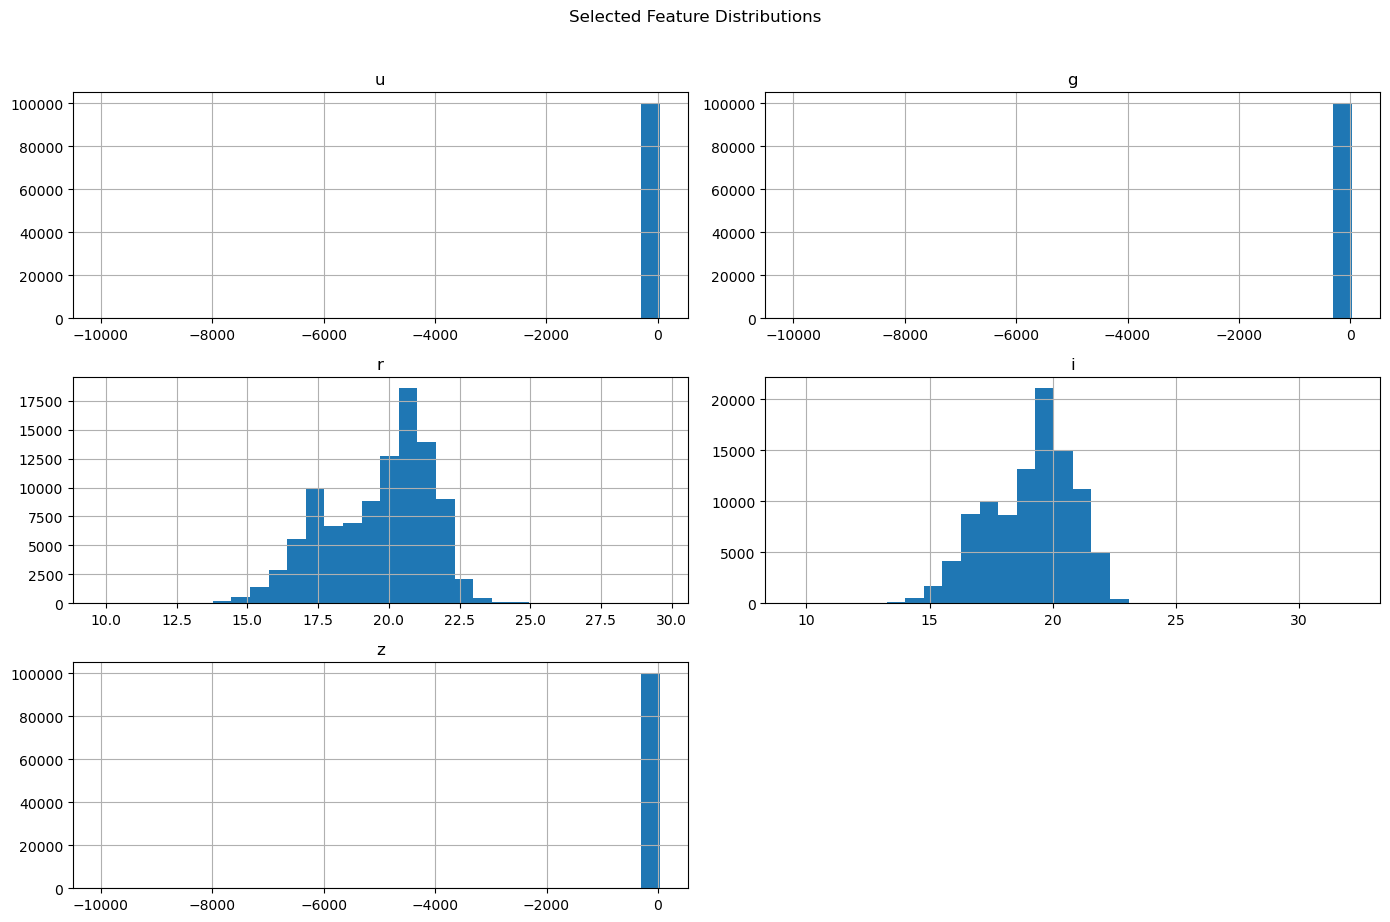

In [11]:
X.hist(bins=30, figsize=(14, 9))
plt.suptitle("Selected Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## 6. Outlier analysis

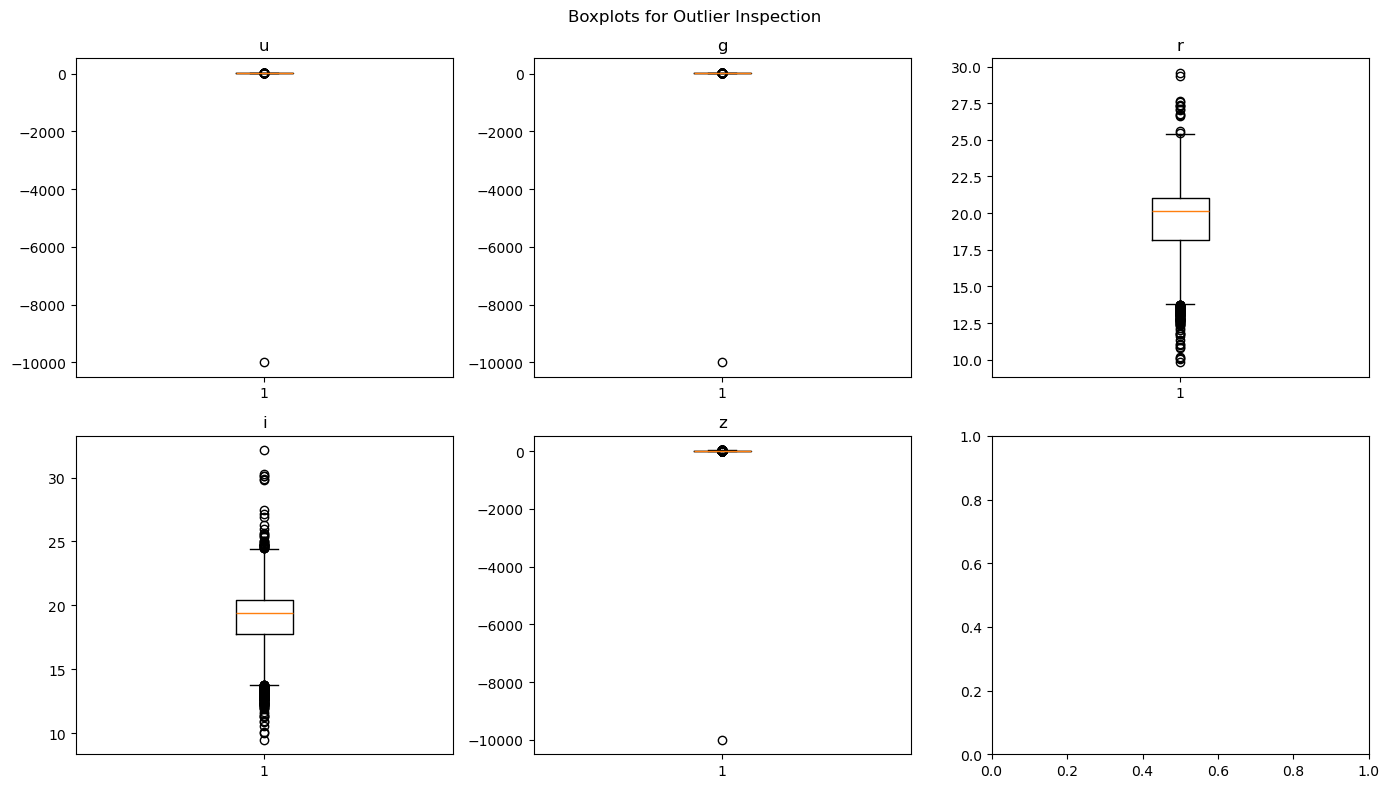

,Feature,Q1,Q3,IQR,Outlier count,Outlier %
0,u,20.352353,23.687440,3.335088,56,0.06
1,g,18.965230,22.123767,3.158538,99,0.10
2,r,18.135828,21.044785,2.908957,132,0.13
3,i,17.732285,20.396495,2.664210,198,0.20
4,z,17.460677,19.921120,2.460442,320,0.32


Outliers are inspected, not automatically removed; extreme astronomy values may be meaningful.


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(FEATURES, axes.flatten()):
    ax.boxplot(X[col].dropna(), showfliers=True)
    ax.set_title(col)
plt.suptitle("Boxplots for Outlier Inspection")
plt.tight_layout()
plt.show()

rows = []
for col in FEATURES:
    values = X[col].dropna()
    q1, q3 = values.quantile(.25), values.quantile(.75)
    iqr = q3 - q1
    count = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    rows.append([col, q1, q3, iqr, count, round(count / max(len(values), 1) * 100, 2)])
display(pd.DataFrame(rows, columns=["Feature", "Q1", "Q3", "IQR", "Outlier count", "Outlier %"]))
print("Outliers are inspected, not automatically removed; extreme astronomy values may be meaningful.")

## 7. Correlation heatmap

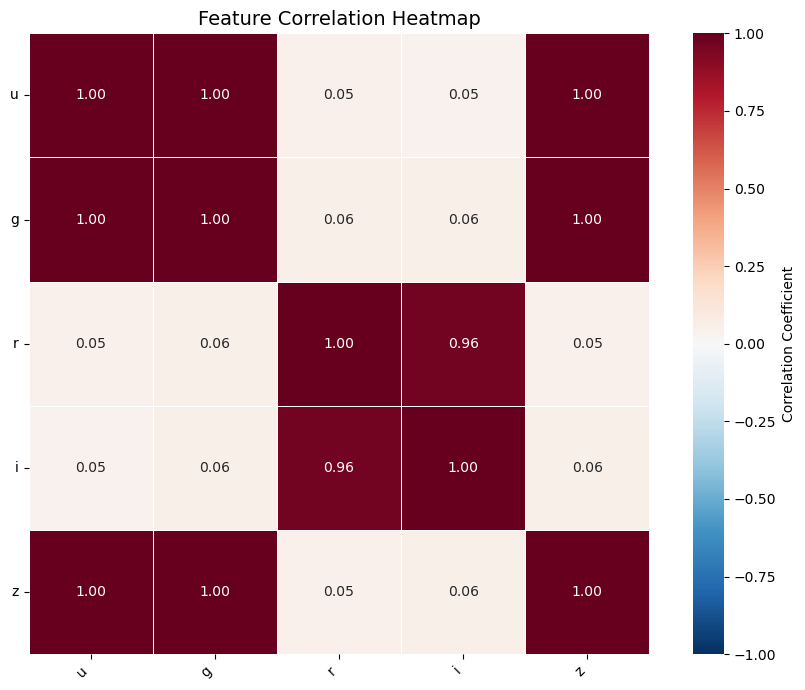

In [28]:
# FEATURE CORRELATION HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt

corr = X.corr(numeric_only=True)

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Feature Correlation Heatmap", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Feature values by class

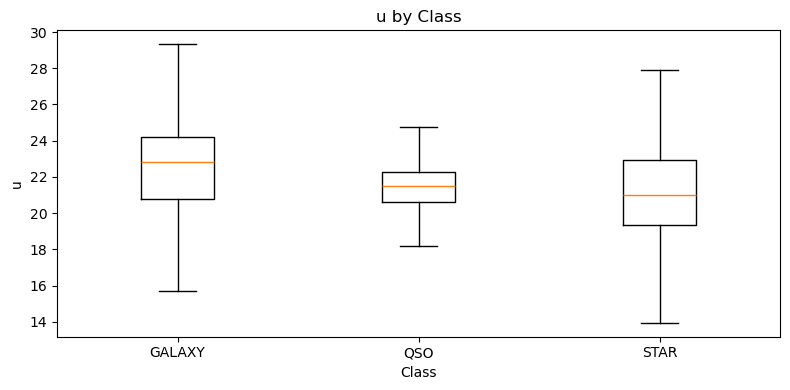

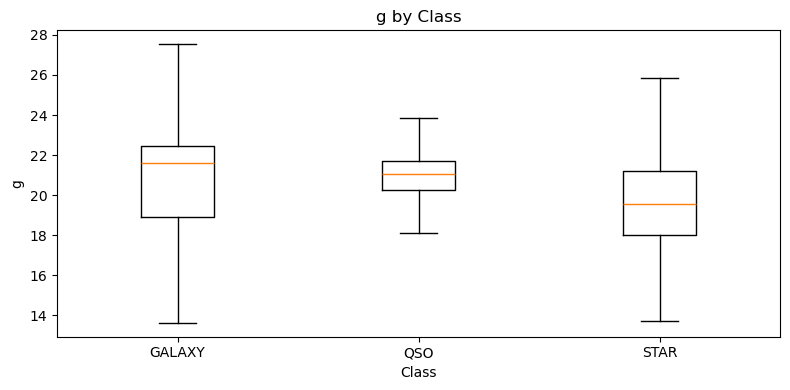

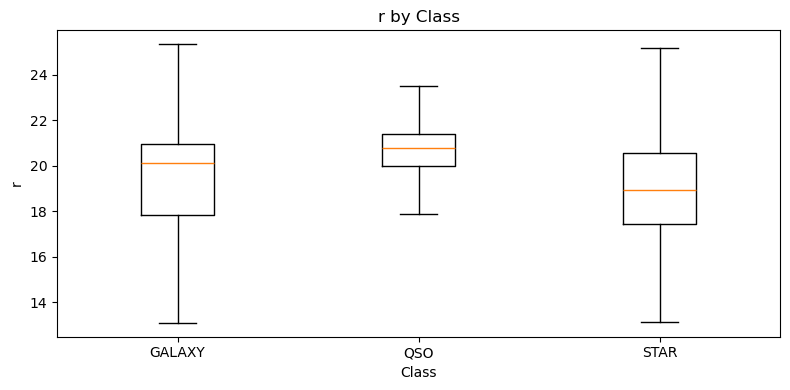

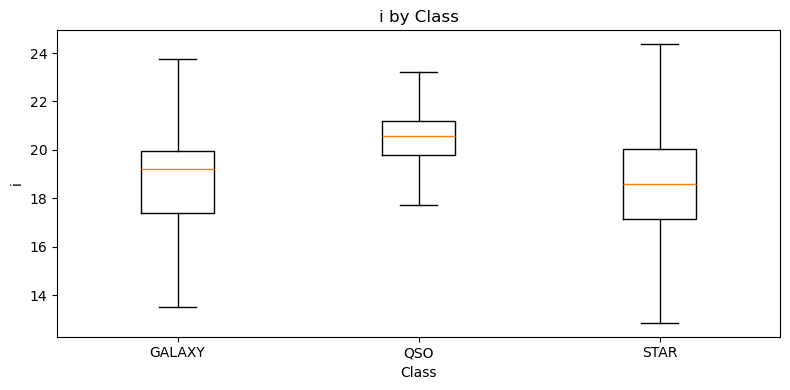

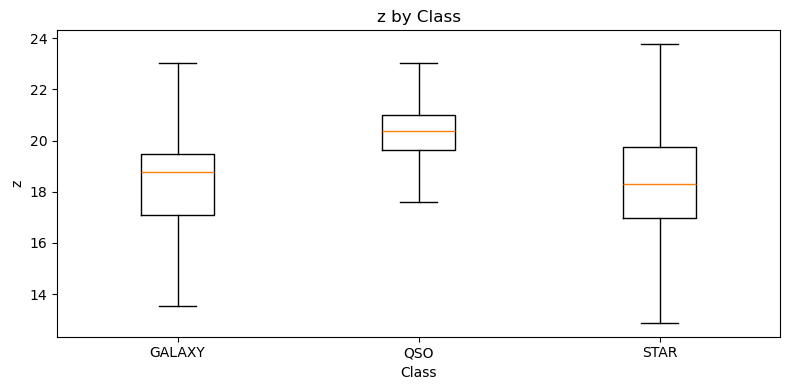

In [14]:
for col in FEATURES:
    labels = sorted(y.unique())
    values = [X.loc[y == label, col].dropna().values for label in labels]
    plt.figure(figsize=(8, 4))
    plt.boxplot(values, labels=labels, showfliers=False)
    plt.title(f"{col} by Class")
    plt.xlabel("Class")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 9. Train-test split and preprocessing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train class proportions:")
print(y_train.value_counts(normalize=True).round(3))



Training rows: 80000
Testing rows: 20000
Train class proportions:
class
GALAXY    0.594
STAR      0.216
QSO       0.190
Name: proportion, dtype: float64


In [17]:
# INITIALIZE MODEL STORAGE

results = []
trained_models = {}
predictions = {}

## 11. Model 1 — Decision Tree

DECISION TREE
              precision    recall  f1-score   support

      GALAXY       0.88      0.88      0.88     11889
         QSO       0.72      0.72      0.72      3792
        STAR       0.71      0.71      0.71      4319

    accuracy                           0.81     20000
   macro avg       0.77      0.77      0.77     20000
weighted avg       0.81      0.81      0.81     20000



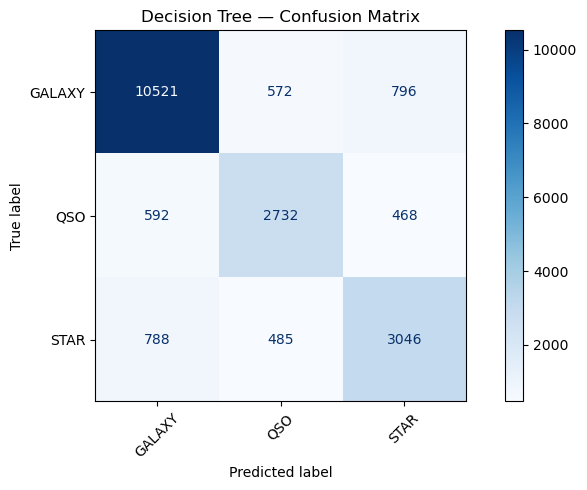

In [18]:
# DECISION TREE

dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

start = time.time()
dt_pipeline.fit(X_train, y_train)
dt_time = time.time() - start

dt_pred = dt_pipeline.predict(X_test)

trained_models["Decision Tree"] = dt_pipeline
predictions["Decision Tree"] = dt_pred

results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Macro Precision": precision_score(y_test, dt_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, dt_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, dt_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, dt_pred, average="weighted", zero_division=0),
    "Training Time (seconds)": dt_time
})

print("DECISION TREE")
print(classification_report(y_test, dt_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred,
    labels=sorted(y.unique()),
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)
plt.title("Decision Tree — Confusion Matrix")
plt.tight_layout()
plt.show()

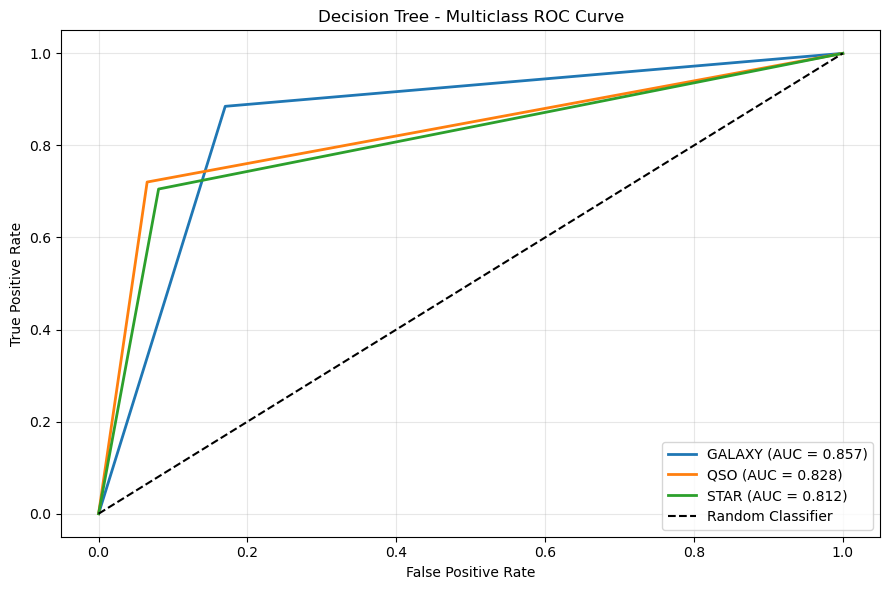

In [31]:
# DECISION TREE - ROC CURVE

classes = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=classes)

dt_prob = dt_pipeline.predict_proba(X_test)

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        dt_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree - Multiclass ROC Curve")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Model 2 — Random Forest

RANDOM FOREST
              precision    recall  f1-score   support

      GALAXY       0.92      0.93      0.93     11889
         QSO       0.80      0.81      0.80      3792
        STAR       0.81      0.77      0.79      4319

    accuracy                           0.87     20000
   macro avg       0.84      0.84      0.84     20000
weighted avg       0.87      0.87      0.87     20000



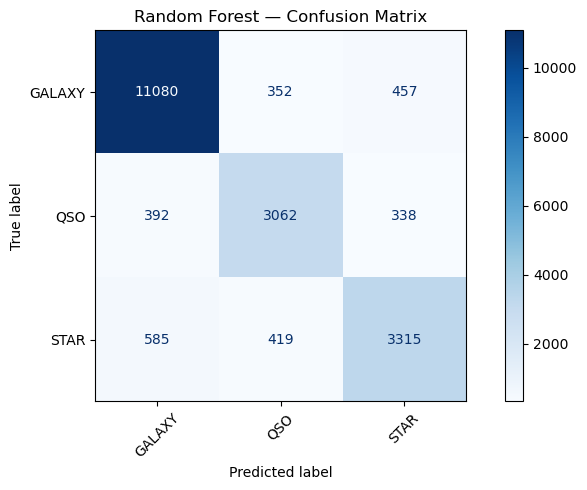

In [19]:
# RANDOM FOREST - OPTIMIZED VERSION

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=20,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced_subsample"
    ))
])

start = time.time()
rf_pipeline.fit(X_train, y_train)
rf_time = time.time() - start

rf_pred = rf_pipeline.predict(X_test)

trained_models["Random Forest"] = rf_pipeline
predictions["Random Forest"] = rf_pred

results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Macro Precision": precision_score(y_test, rf_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, rf_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, rf_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, rf_pred, average="weighted", zero_division=0),
    "Training Time (seconds)": rf_time
})

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    labels=sorted(y.unique()),
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

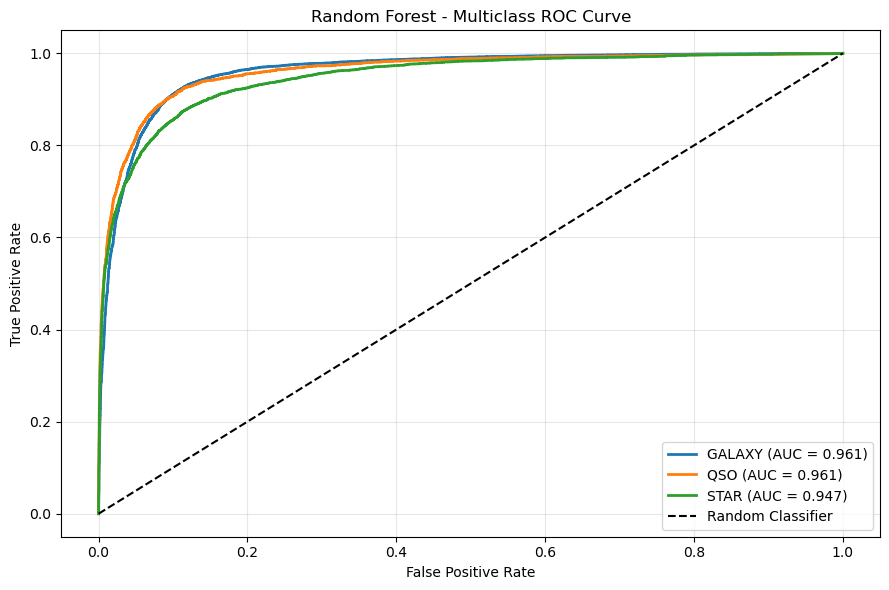

In [32]:
# RANDOM FOREST - ROC CURVE

rf_prob = rf_pipeline.predict_proba(X_test)

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        rf_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - Multiclass ROC Curve")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Model 3 — SVM

SUPPORT VECTOR MACHINE
              precision    recall  f1-score   support

      GALAXY       0.89      0.87      0.88     11889
         QSO       0.64      0.86      0.73      3792
        STAR       0.73      0.53      0.61      4319

    accuracy                           0.80     20000
   macro avg       0.75      0.76      0.74     20000
weighted avg       0.80      0.80      0.79     20000



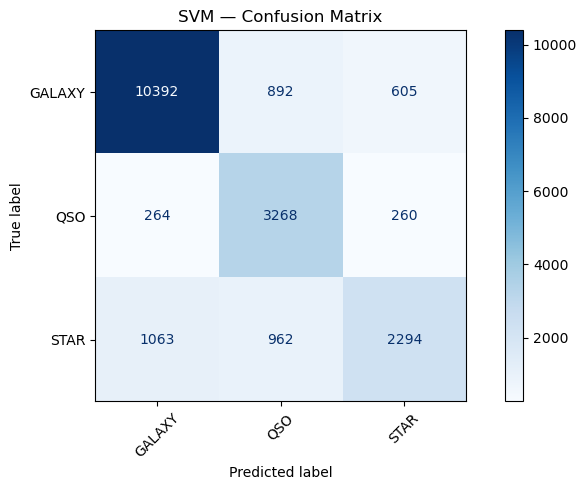

In [20]:
# SUPPORT VECTOR MACHINE

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=3,
        class_weight="balanced"
    ))
])

start = time.time()
svm_pipeline.fit(X_train, y_train)
svm_time = time.time() - start

svm_pred = svm_pipeline.predict(X_test)

trained_models["SVM"] = svm_pipeline
predictions["SVM"] = svm_pred

results.append({
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Macro Precision": precision_score(y_test, svm_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, svm_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, svm_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, svm_pred, average="weighted", zero_division=0),
    "Training Time (seconds)": svm_time
})

print("SUPPORT VECTOR MACHINE")
print(classification_report(y_test, svm_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    labels=sorted(y.unique()),
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)
plt.title("SVM — Confusion Matrix")
plt.tight_layout()
plt.show()

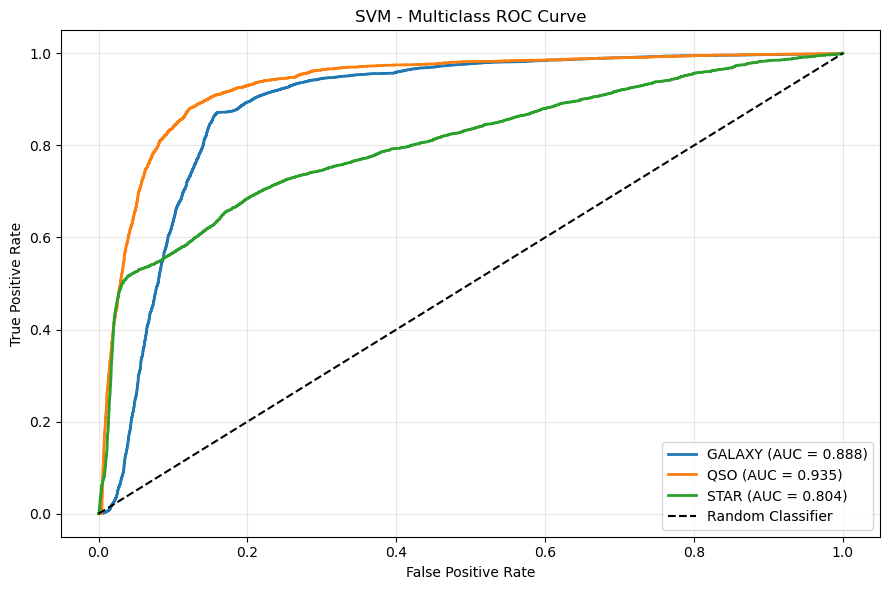

In [ ]:
classes = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=classes)

# Get SVM decision scores
svm_scores = svm_pipeline.decision_function(X_test)

# Plot ROC curve for each class
plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        svm_scores[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

    
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM - Multiclass ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Model 4 — Gradient Boosting

  File "c:\Users\aarya\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\aarya\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aarya\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aarya\anaconda3\Lib\subprocess.

GRADIENT BOOSTING
              precision    recall  f1-score   support

      GALAXY       0.90      0.94      0.92     11889
         QSO       0.81      0.80      0.80      3792
        STAR       0.81      0.72      0.76      4319

    accuracy                           0.87     20000
   macro avg       0.84      0.82      0.83     20000
weighted avg       0.86      0.87      0.86     20000



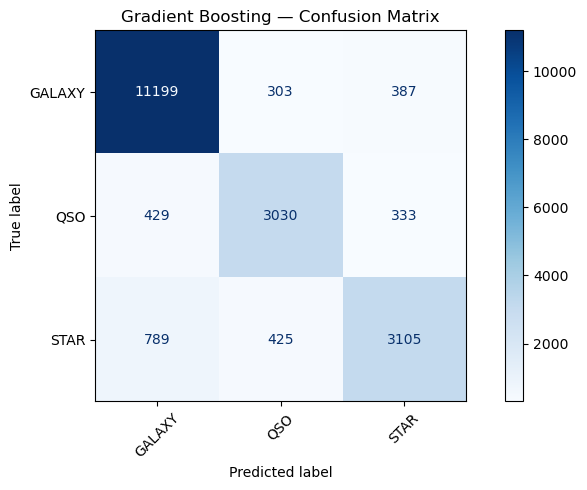

In [21]:
# GRADIENT BOOSTING

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        random_state=RANDOM_STATE
    ))
])

start = time.time()
gb_pipeline.fit(X_train, y_train)
gb_time = time.time() - start

gb_pred = gb_pipeline.predict(X_test)

trained_models["Gradient Boosting"] = gb_pipeline
predictions["Gradient Boosting"] = gb_pred

results.append({
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, gb_pred),
    "Macro Precision": precision_score(y_test, gb_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, gb_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, gb_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, gb_pred, average="weighted", zero_division=0),
    "Training Time (seconds)": gb_time
})

print("GRADIENT BOOSTING")
print(classification_report(y_test, gb_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, gb_pred,
    labels=sorted(y.unique()),
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)
plt.title("Gradient Boosting — Confusion Matrix")
plt.tight_layout()
plt.show()

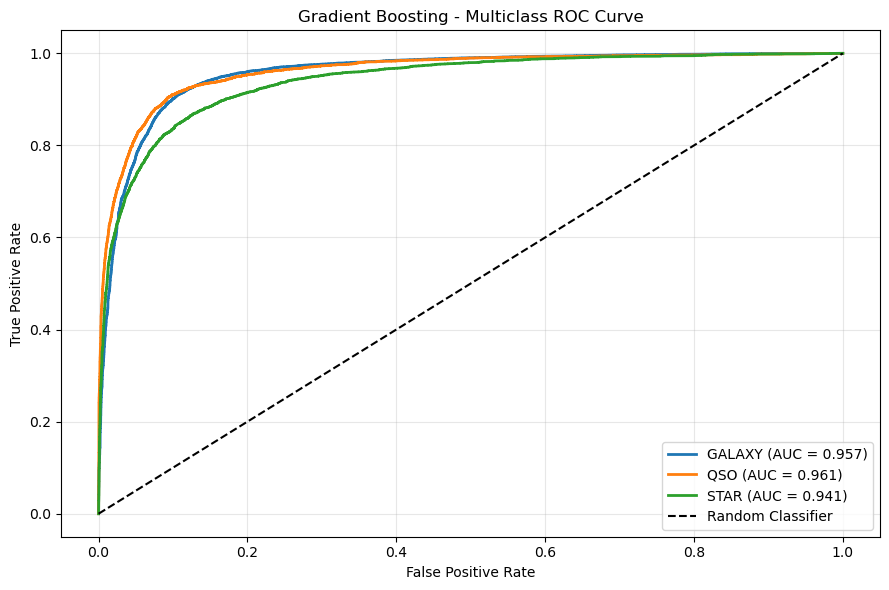

In [34]:
# GRADIENT BOOSTING - MULTICLASS ROC CURVE

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Convert actual labels into binary format
classes = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=classes)

# Get prediction probabilities
gb_prob = gb_pipeline.predict_proba(X_test)

# Plot ROC curve for each class
plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        gb_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting - Multiclass ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Compare all models

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (seconds)
0,Random Forest,0.8728,0.8415,0.8357,0.8384,0.8722,2.1270
1,Gradient Boosting,0.8667,0.8400,0.8200,0.8289,0.8646,4.7576
2,Decision Tree,0.8149,0.7706,0.7702,0.7704,0.8149,1.8103
3,SVM,0.7977,0.7503,0.7557,0.7424,0.7949,280.3625


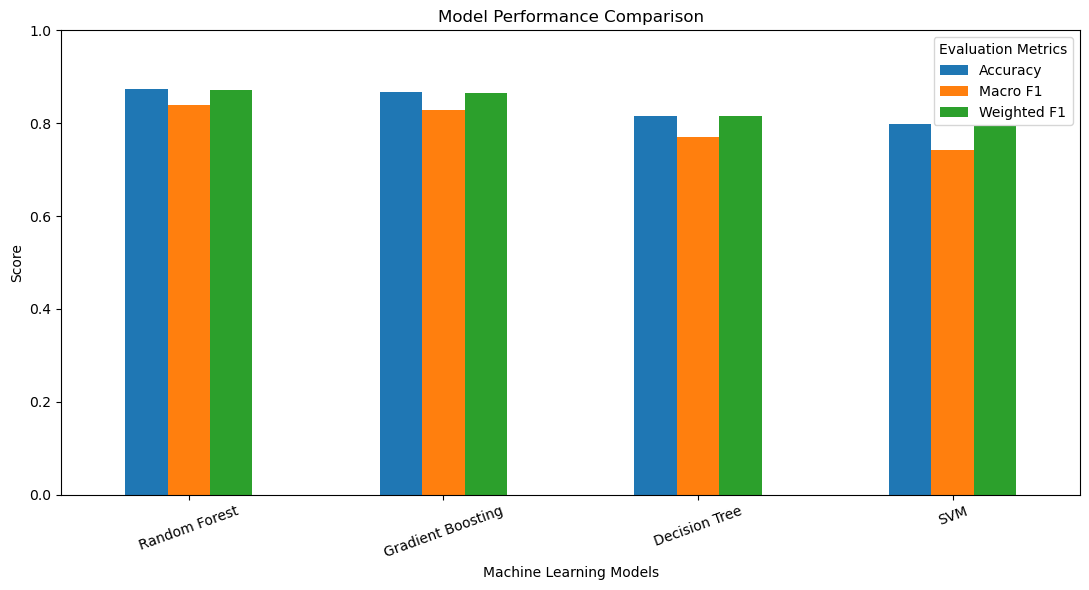

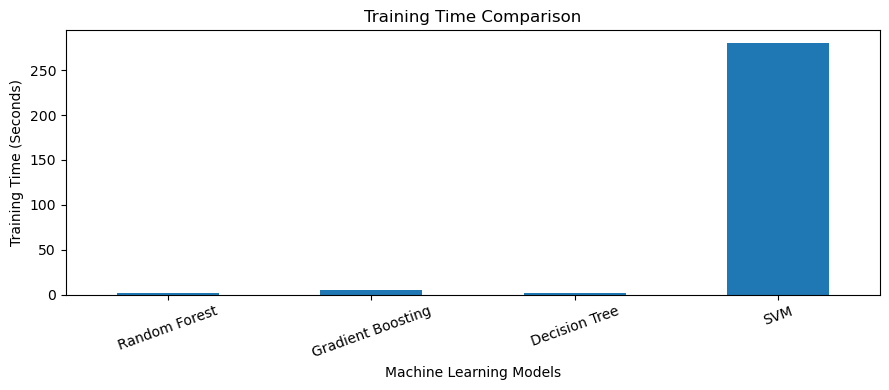

In [22]:
# MODEL PERFORMANCE COMPARISON

results_df = pd.DataFrame(results).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


# GRAPH 1: MODEL PERFORMANCE COMPARISON

results_df.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()


# GRAPH 2: TRAINING TIME COMPARISON

results_df.set_index("Model")["Training Time (seconds)"].plot(
    kind="bar",
    figsize=(9, 4)
)

plt.title("Training Time Comparison")
plt.ylabel("Training Time (Seconds)")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

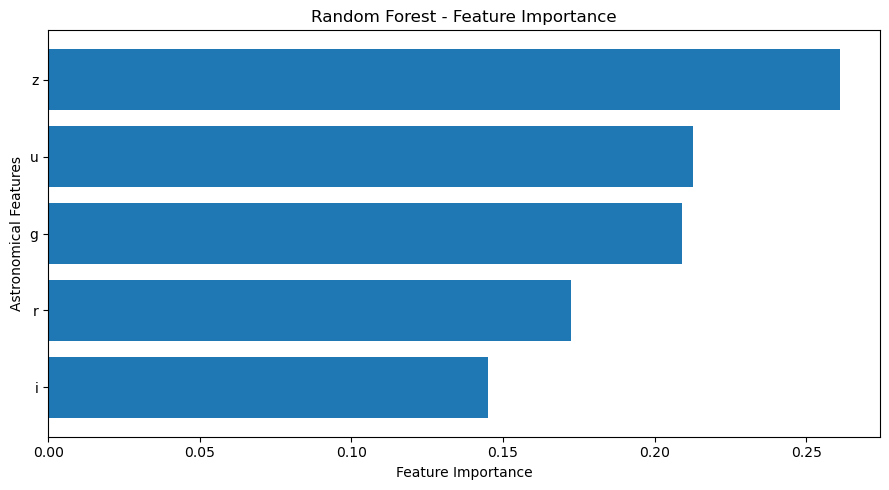

In [29]:
rf_estimator = rf_pipeline.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_estimator.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Astronomical Features")
plt.title("Random Forest - Feature Importance")

plt.tight_layout()
plt.show()

## 16. Save models and best model

In [23]:
# SAVE TRAINED MODELS AND METADATA

import os
import json
import joblib

os.makedirs("saved_models", exist_ok=True)

# Save each trained model
for name, pipeline in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        pipeline,
        os.path.join("saved_models", filename),
        compress=3
    )

    print(f"{name} saved successfully!")


# Select the best model using Macro F1
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

# Save the best model with the filename expected by app.py
joblib.dump(
    best_model,
    "saved_models/best_star_classifier.joblib",
    compress=3
)


# Create model metadata
metadata = {
    "best_model": best_name,
    "features": FEATURES,
    "target": TARGET,
    "classes": sorted(y.unique()),
    "selection_metric": "Macro F1",
    "test_metrics": results_df.iloc[0].to_dict()
}

# Save metadata as JSON
with open("saved_models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=float)


print("\nBest Model:", best_name)
print("Best Macro F1:", round(results_df.iloc[0]["Macro F1"], 4))
print("All models and metadata saved successfully!")

Decision Tree saved successfully!
Random Forest saved successfully!
SVM saved successfully!
Gradient Boosting saved successfully!

Best Model: Random Forest
Best Macro F1: 0.8384
All models and metadata saved successfully!


## 17. Predict a new sample

In [24]:
# Example values are placeholders for demonstrating prediction.
new_sample = pd.DataFrame([{
    "u": 22.3, "g": 21.8, "r": 21.2, "i": 20.9, "z": 20.7
}])[FEATURES]
print("Predicted class:", best_model.predict(new_sample)[0])
if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(new_sample)[0]
    print(dict(zip(best_model.classes_, probs.round(4))))

Predicted class: QSO
{'GALAXY': np.float64(0.3427), 'QSO': np.float64(0.5673), 'STAR': np.float64(0.0901)}


In [26]:
from pathlib import Path

save_path = Path("saved_models/model_comparison.json")
save_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_json(
    save_path,
    orient="records",
    indent=2
)

print("File created:", save_path.resolve())
print("Exists:", save_path.exists())

File created: D:\ML_FINAL_FINAL\star_classification_project\saved_models\model_comparison.json
Exists: True


In [36]:
# RUN THIS CELL AFTER rf_pipeline, rf_pred, rf_prob AND results_df HAVE BEEN CREATED
import json
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

classes = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=classes)
rf_prob = rf_pipeline.predict_proba(X_test)

# Confusion matrix: actual labels by predicted labels
cm = confusion_matrix(y_test, rf_pred, labels=classes)

# One-vs-rest ROC curve data for each class
roc_data = []
for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], rf_prob[:, i])
    roc_data.append({
        "class": str(class_name),
        "auc": float(auc(fpr, tpr)),
        # Limit points for a compact JSON file while preserving curve shape
        "points": [[float(x), float(y_value)] for x, y_value in zip(fpr[::max(1, len(fpr)//250)], tpr[::max(1, len(tpr)//250)])]
    })

# Random Forest feature importance
rf_estimator = rf_pipeline.named_steps["model"]
feature_importance = [
    {"feature": str(feature), "importance": float(value)}
    for feature, value in zip(FEATURES, rf_estimator.feature_importances_)
]
feature_importance.sort(key=lambda item: item["importance"], reverse=True)

# Pull the Random Forest row from the existing model comparison table
rf_row = results_df.loc[results_df["Model"] == "Random Forest"].iloc[0]
metrics = {
    "accuracy": float(rf_row["Accuracy"]),
    "macro_precision": float(rf_row["Macro Precision"]),
    "macro_recall": float(rf_row["Macro Recall"]),
    "macro_f1": float(rf_row["Macro F1"]),
    "weighted_f1": float(rf_row["Weighted F1"])
}

export_data = {
    "model": "Random Forest",
    "classes": [str(label) for label in classes],
    "confusion_matrix": cm.tolist(),
    "roc": roc_data,
    "feature_importance": feature_importance,
    "metrics": metrics
}

output_path = Path("saved_models/random_forest_analysis.json")
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(json.dumps(export_data, indent=2), encoding="utf-8")
print("Random Forest analysis exported:", output_path.resolve())
print("Confusion matrix, ROC curves, feature importance and test metrics saved.")


Random Forest analysis exported: D:\ML_FINAL_FINAL\star_classification_project\saved_models\random_forest_analysis.json
Confusion matrix, ROC curves, feature importance and test metrics saved.
